# **Neural Networks for Handwritten Digit Recognition using the MNIST Dataset**

#### Raul Almuzara

------------------------

### *INTRODUCTION*

We will work with neural networks for image classification. The aim is to obtain models capable of making reliable predictions on images from the well-known MNIST dataset of 28×28 pixel images of handwritten digits in grayscale. For this purpose, we will use some images of digits as training and validation sets, and we are looking for models that perform well on test data that the model has never seen before

We will use ``TensorFlow`` to train the neural networks. The selected models will be a MultiLayer Perceptron (MLP), a Gated Recurrent Unit network (GRU) and a Convolutional Neural Network (CNN)

------------------------

### *SETUP*

*In this section, we import libraries, import the specific modules made for this project and set seeds for reproducibility*

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report

os.environ['PYTHONHASHSEED']=str(42)
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

from modules.preprocess_data import (
    read_dataset, 
    plot_overview_dataset, 
    split_dataset, 
    shuffle_instances, 
    separate_features_labels, 
    pd_to_tf_dataset, 
    batch_dataset, 
    prepare_early_stopping,
    reshape_dataset_for_mlp, 
    reshape_dataset_for_gru, 
    reshape_dataset_for_cnn
)

from modules.nn_models import (
    MLP_model, 
    GRU_model, 
    CNN_model
)

from modules.fit_models import (
    fit_model
)

from modules.analyze_models import (
    plot_training_history, 
    get_model_predictions, 
    show_confusion_matrix, 
    show_classification_report, 
    plot_top_confident_wrong_predictions
)

------------------------

### *PREPROCESSING*

*In this section, we read the MNIST data and prepare the training, validation and test datasets that will later be used for training and testing*

In this case, the data comes in two separate CSV files (decompress them if in ZIP format), one for training and one for testing. Both contain 785 columns:
- Column 1 contains the labels indicating digits from 0 to 9
- Columns 2-785 contain the grayscale pixel values from 0 to 255

In [2]:
df_train_original, df_test_original = read_dataset('datasets/mnist_train-e.csv', 'datasets/mnist_test-e.csv')

In [3]:
df_train_original.head()

,1,2,3,4,5,6,7,8,9,10,...,776,777,778,779,780,781,782,783,784,785
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df_test_original.head()

,1,2,3,4,5,6,7,8,9,10,...,776,777,778,779,780,781,782,783,784,785
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Below are some examples of digits from the dataset

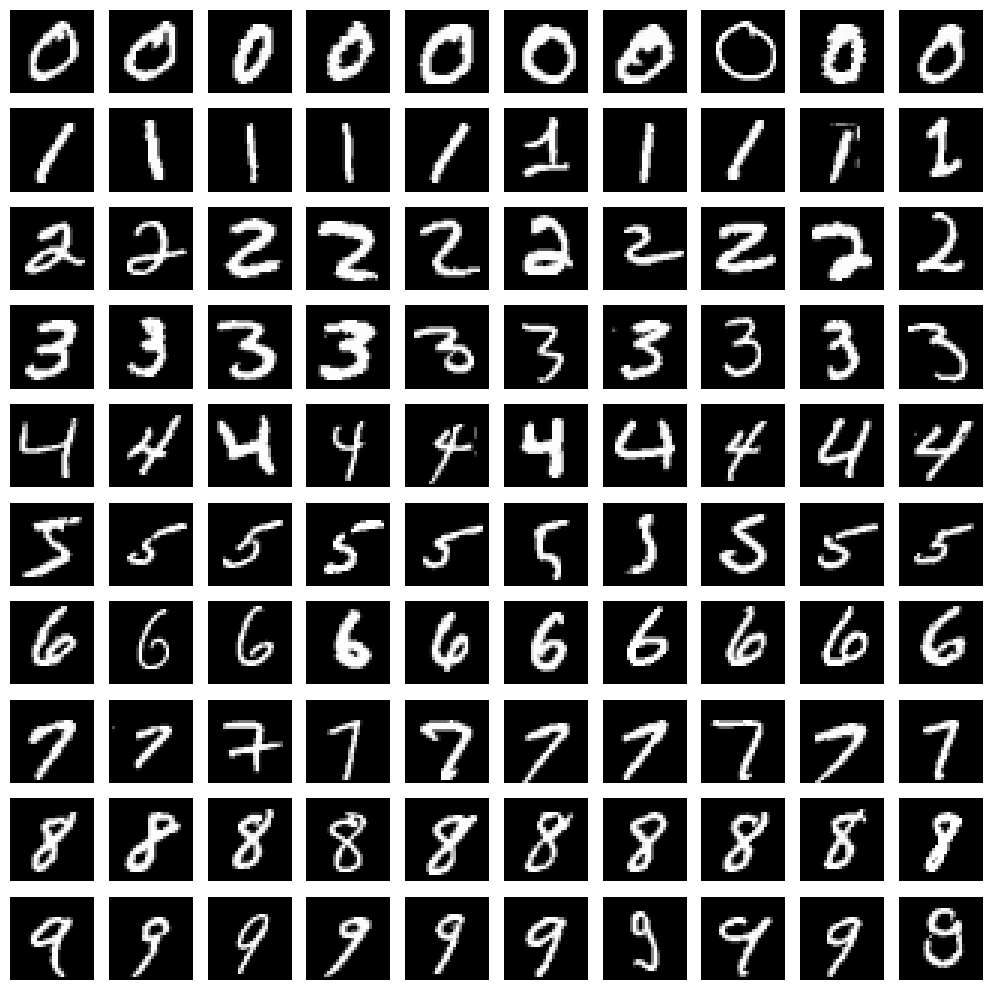

In [5]:
plot_overview_dataset(df_train_original)

Originally, we had 60000 training instances and 10000 test instances. To build the validation set, we have chosen to extract 10000 instances from the training data CSV (1/6). Therefore, we will have 50000 instances in the training set and 10000 instances in the validation set. Finally, we keep the 10000 instances in the test data CSV to build the test set

In [6]:
df_train_new, df_validation_new = split_dataset(df_train_original, 1/6)

In [7]:
print(f'{len(df_train_new)} train + {len(df_validation_new)} validation + {len(df_test_original)} test')

50000 train + 10000 validation + 10000 test


We shuffle the images to ensure that there are no dependencies between adjacent instances and that they have not been grouped in a specific order

In [8]:
df_train, df_validation, df_test = shuffle_instances(df_train_new, df_validation_new, df_test_original)

We separate the column containing the digit labels from the columns containing the pixels. In this case, the numbers in the predictors represent the gray level associated with each of the 28×28=784 pixels in an image. The gray level of a pixel is between 0 and 255. A straightforward transformation is to divide the value of each pixel of all images by 255 to adjust the scale to the interval [0,1], which is easier for the network to handle. This transformation is done on each of the 784 variables representing the pixels.

In [9]:
X_train, X_validation, X_test, y_train, y_validation, y_test = separate_features_labels(df_train, df_validation, df_test)

We construct TensorFlow objects that group predictor variables and the target variable together

In [10]:
train_dataset, validation_dataset, test_dataset = pd_to_tf_dataset(X_train, X_validation, X_test, y_train, y_validation, y_test)

We prepare the data in batches for a more efficient training process

In [11]:
train_data, validation_data, test_data = batch_dataset(train_dataset, 32, validation_dataset, 256, test_dataset, 256)

Each specific model will require the input to have specific dimensions and we must resize the input accordingly

Specifically, the MLP model expects a flat input of size 784, so we reshape our data

In [12]:
train_data_mlp, validation_data_mlp, test_data_mlp = reshape_dataset_for_mlp(train_data, validation_data, test_data)

Specifically, the GRU model expects an input of size 28×28, so we reshape our data

In [13]:
train_data_gru, validation_data_gru, test_data_gru = reshape_dataset_for_gru(train_data, validation_data, test_data)

Specifically, the CNN model expects an input of size 28×28×1, so we reshape our data

In [14]:
train_data_cnn, validation_data_cnn, test_data_cnn = reshape_dataset_for_cnn(train_data, validation_data, test_data)

We will also stop training if validation loss starts to increase, so we avoid overfitting

In [15]:
callbacks = prepare_early_stopping(patience=1)

------------------------

### *MODELS*

*In this section, we train each of the three models (MLP, GRU and CNN), we evaluate them on the test set and we assess their performance*

--

#### *MLP model*

MultiLayer Perceptrons are basic feedforward neural networks

In this notebook, the proposed MLP receives as input a flattened vector of 784 values. There are two hidden layers with 512 and 256 neurons, respectively, whose weights are initialized using the He Normal initializer to suit the ReLU activation function. Each hidden layer is followed by Batch Normalization, which stabilizes and accelerates training by normalizing the Dense layer outputs, then a ReLU activation layer that introduces non-linearity and a Dropout layer with a rate of 0.1 to reduce overfitting. The output layer contains 10 neurons, one for each digit class, uses the Softmax activation function to produce class probabilities, and employs Glorot Uniform weight initialization, which is well suited for the output layer. The model is trained using the Adam optimizer with a learning rate of 0.0001, minimizing the sparse categorical cross-entropy loss function while monitoring classification accuracy as the evaluation metric

We train the MLP model

In [16]:
model_mlp, trace_mlp = fit_model(MLP_model(), train_data_mlp, validation_data_mlp, 20, callbacks, 'trained_models/trained-MLP.keras')

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               401920    
                                                                 
 batch_normalization (BatchN  (None, 512)              2048      
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 512)               0         
                                                                 
 dropout (Dropout)           (None, 512)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               131328    
                                                                 
 batch_normalization_1 (Batc  (None, 256)              1024      
 hNormalization)                                        

Visualization of the learning curves for training loss and training accuracy (blue) and validation loss and validation accuracy (orange)

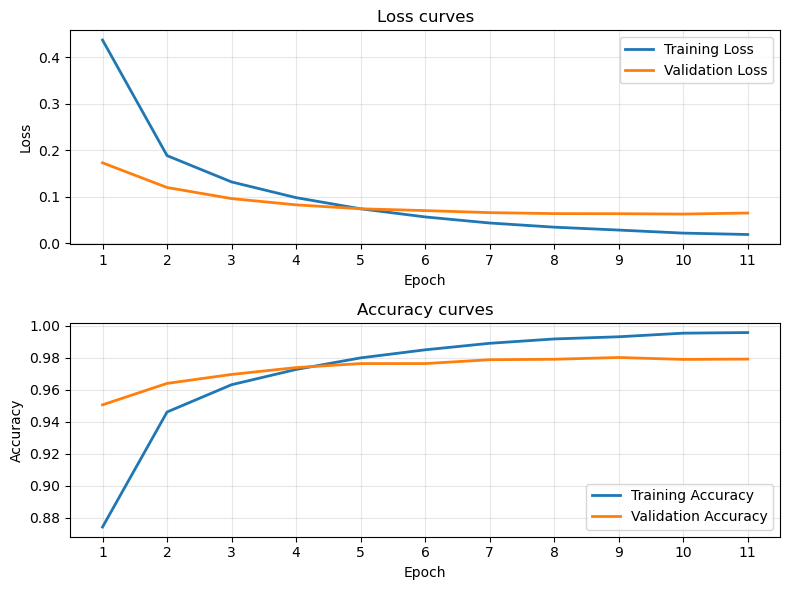

In [17]:
plot_training_history(trace_mlp)

The training process was successful, demonstrating good model convergence and strong generalization on the MNIST dataset with negligible overfitting. In the loss curves, the training loss drops sharply from around 0.44 to around 0.02, while the validation loss decreases steadily from around 0.17 before flattening out around 0.06. Mirroring this positive trend, the training accuracy climbs smoothly from 87% to around 99.5%, while the validation accuracy stabilizes at a very high 98%. Because the validation metrics plateau smoothly rather than worsening as training progresses, the tight, stable gap between the blue and orange lines proves that the MultiLayer Perceptron generalizes well to unseen data

Once the MLP model has been trained, we test it by having it make predictions on the images in the test set

In [18]:
test_loss_mlp, test_accuracy_mlp, probabilities_mlp, y_pred_mlp = get_model_predictions(model_mlp, test_data_mlp)

In [19]:
print(f'Test loss: {test_loss_mlp:.4f}\nTest accuracy: {test_accuracy_mlp:.4f}')

Test loss: 0.0632
Test accuracy: 0.9804


The accuracy (or the percentage of correctly predicted handwritten digits) is **98.04%**

In the following confusion matrix, each row is the true digit, each column is the predicted digit, and each cell shows the count of test samples with that true digit classified as that predicted digit

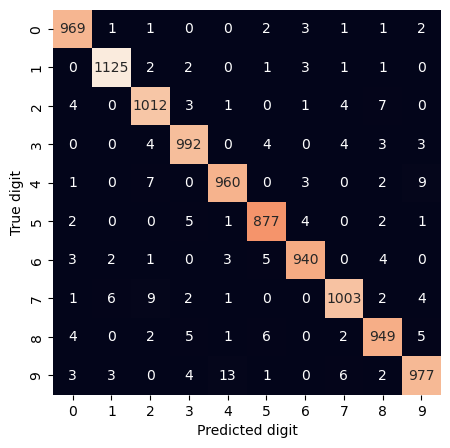

In [20]:
show_confusion_matrix(y_test, y_pred_mlp)

Here is a classification report with some additional per-class metrics

In [21]:
show_classification_report(y_test, y_pred_mlp)

              precision    recall  f1-score   support

           0     0.9818    0.9888    0.9853       980
           1     0.9894    0.9912    0.9903      1135
           2     0.9750    0.9806    0.9778      1032
           3     0.9793    0.9822    0.9807      1010
           4     0.9796    0.9776    0.9786       982
           5     0.9788    0.9832    0.9810       892
           6     0.9853    0.9812    0.9833       958
           7     0.9824    0.9757    0.9790      1028
           8     0.9753    0.9743    0.9748       974
           9     0.9760    0.9683    0.9721      1009

    accuracy                         0.9804     10000
   macro avg     0.9803    0.9803    0.9803     10000
weighted avg     0.9804    0.9804    0.9804     10000



We might also be interested in the digits that the MLP model incorrectly predicted with the highest confidence (very high probability in the winning class, even if it was not the right one). This is important for determining whether the model has any critical flaws or if some of the digits are simply poorly drawn

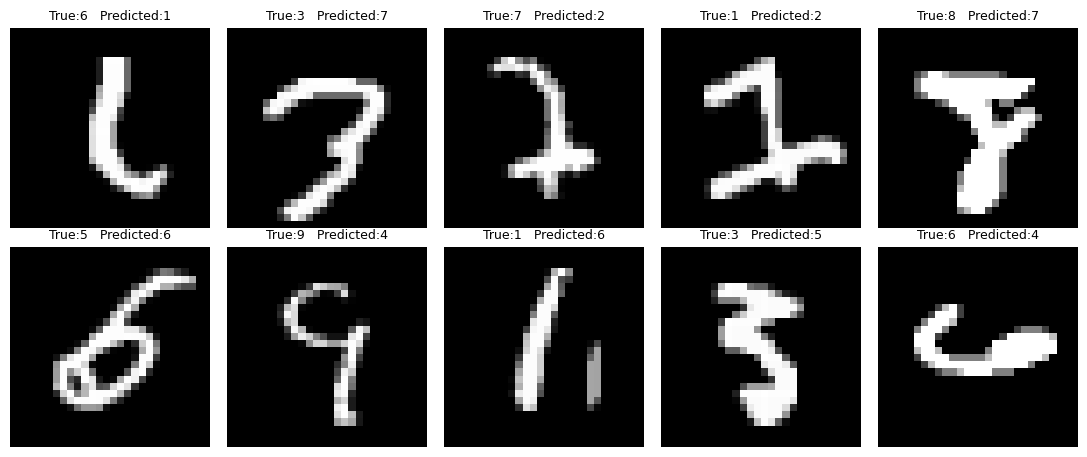

In [22]:
plot_top_confident_wrong_predictions(X_test, y_test, probabilities_mlp, y_pred_mlp, 10)

It is not hard to see why the MLP model gets some specific examples wrong, since even a human might make similar mistakes when looking at digits drawn with unclear strokes

------------------------

#### *GRU model*

Gated Recurrent Unit models are a type of Recurrent Neural Network and they are designed to process sequential data

The proposed GRU network receives as input each handwritten digit as a sequence of 28 time steps, where each time step corresponds to one row of the 28×28 grayscale image and contains 28 pixel values. The recurrent feature extraction stage consists of two stacked GRU layers with 128 and 64 units, respectively. The first GRU layer is configured with return_sequences=True so that it outputs the complete sequence to the second GRU layer, enabling the network to learn hierarchical sequential representations. Both recurrent layers use Glorot Uniform initialization for the input kernel and Orthogonal initialization for the recurrent kernel, a combination that is well suited to the internal tanh and sigmoid activation functions of GRU cells and helps preserve stable hidden-state dynamics during training. They also incorporate both dropout and recurrent dropout with a rate of 0.2 to regularize the input and recurrent connections, thereby reducing overfitting. The features extracted by the recurrent layers are then passed to a Dense layer with 64 neurons using the ReLU activation function and He Normal initialization, providing a nonlinear classifier before the final prediction stage. An additional Dropout layer with a rate of 0.2 further improves generalization. Finally, the output layer consists of 10 neurons with a Softmax activation function and Glorot Uniform initialization, producing the probability distribution over the ten digit classes. The model is trained using the Adam optimizer with a learning rate of 0.0001, minimizing the sparse categorical cross-entropy loss function while monitoring classification accuracy as the evaluation metric

We train the GRU model

In [23]:
model_gru, trace_gru = fit_model(GRU_model(), train_data_gru, validation_data_gru, 20, callbacks, 'trained_models/trained-GRU.keras')

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 gru (GRU)                   (None, 28, 128)           60672     
                                                                 
 gru_1 (GRU)                 (None, 64)                37248     
                                                                 
 dense_3 (Dense)             (None, 64)                4160      
                                                                 
 dropout_2 (Dropout)         (None, 64)                0         
                                                                 
 dense_4 (Dense)             (None, 10)                650       
                                                                 
Total params: 102,730
Trainable params: 102,730
Non-trainable params: 0
_________________________________________________________________
Epoch 1/20
1563/1563 [==========================

Visualization of the learning curves for training loss and training accuracy (blue) and validation loss and validation accuracy (orange)

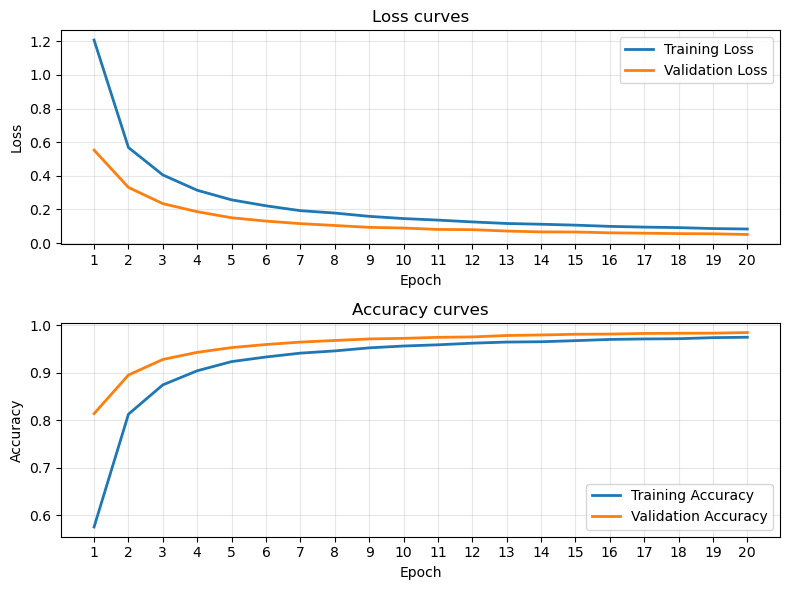

In [24]:
plot_training_history(trace_gru)

The training for this GRU model went well and indicates a highly stable learning. In the loss curves, the training loss drops smoothly from approximately 1.21 down to 0.08, while the validation loss decreases from 0.55 before leveling off near 0.05. The validation loss remains consistently lower than the training loss, which is mirrored directly in the accuracy curves where validation accuracy sits above training accuracy throughout the entire run, finalizing at roughly 98.5% compared to training's 97.5%. Ultimately, the parallel, downward-trending loss lines and upward-trending accuracy lines prove that the model converged smoothly without notable signs of overfitting

Once the GRU model has been trained, we test it by having it make predictions on the images in the test set

In [25]:
test_loss_gru, test_accuracy_gru, probabilities_gru, y_pred_gru = get_model_predictions(model_gru, test_data_gru)

In [26]:
print(f'Test loss: {test_loss_gru:.4f}\nTest accuracy: {test_accuracy_gru:.4f}')

Test loss: 0.0479
Test accuracy: 0.9854


The accuracy (or the percentage of correctly predicted handwritten digits) is **98.54%**

In the following confusion matrix, each row is the true digit, each column is the predicted digit, and each cell shows the count of test samples with that true digit classified as that predicted digit

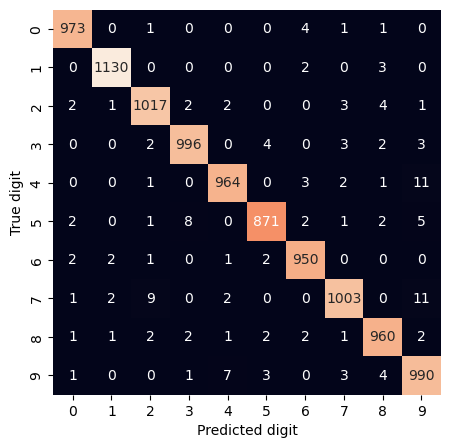

In [27]:
show_confusion_matrix(y_test, y_pred_gru)

Here is a classification report with some additional per-class metrics

In [28]:
show_classification_report(y_test, y_pred_gru)

              precision    recall  f1-score   support

           0     0.9908    0.9929    0.9918       980
           1     0.9947    0.9956    0.9952      1135
           2     0.9836    0.9855    0.9845      1032
           3     0.9871    0.9861    0.9866      1010
           4     0.9867    0.9817    0.9842       982
           5     0.9875    0.9765    0.9820       892
           6     0.9865    0.9916    0.9891       958
           7     0.9862    0.9757    0.9809      1028
           8     0.9826    0.9856    0.9841       974
           9     0.9677    0.9812    0.9744      1009

    accuracy                         0.9854     10000
   macro avg     0.9854    0.9852    0.9853     10000
weighted avg     0.9854    0.9854    0.9854     10000



We might also be interested in the digits that the GRU model incorrectly predicted with the highest confidence (very high probability in the winning class, even if it was not the right one). This is important for determining whether the model has any critical flaws or if some of the digits are simply poorly drawn

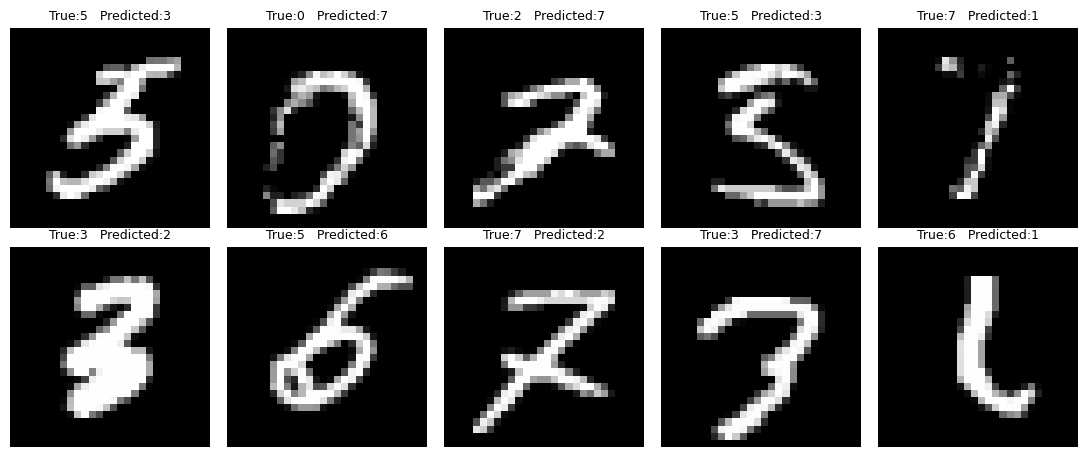

In [29]:
plot_top_confident_wrong_predictions(X_test, y_test, probabilities_gru, y_pred_gru, 10)

It is not hard to see why the GRU model gets some specific examples wrong, since even a human might make similar mistakes when looking at digits drawn with unclear strokes

------------------------

#### *CNN model*

Convolutional Neural Networks are deep learning models designed to process and analyze structured grid data, such as images and video

The proposed CNN receives as input a 28×28×1 grayscale image represented as a single-channel tensor. The feature extraction stage consists of two convolutional blocks. The first block contains two 2D convolutional layers with 32 filters of size 3×3, using He Normal weight initialization and no bias terms. Each convolution is immediately followed by Batch Normalization, which normalizes the feature maps, and then a ReLU activation function to introduce non-linearity. The block concludes with a 2×2 Max Pooling layer to reduce the spatial dimensions of the feature maps and a Dropout layer with a rate of 0.25 to mitigate overfitting. The second block follows the same structure but increases the number of filters to 64, enabling the network to learn more complex and abstract visual features. After the convolutional stage, the resulting feature maps are flattened into a one-dimensional vector and passed to a fully connected layer with 128 neurons, employing ReLU activation and He Normal initialization. A Dropout layer with a rate of 0.5 further regularizes the classifier before the final output layer, which consists of 10 neurons with a Softmax activation function and Glorot Uniform initialization to produce the probability distribution over the ten digit classes. The model is trained using the Adam optimizer with a learning rate of 0.0001, minimizing the sparse categorical cross-entropy loss function while monitoring classification accuracy as the evaluation metric

We train the CNN model

In [30]:
model_cnn, trace_cnn = fit_model(CNN_model(), train_data_cnn, validation_data_cnn, 20, callbacks, 'trained_models/trained-CNN.keras')

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 32)        288       
                                                                 
 batch_normalization_2 (Batc  (None, 28, 28, 32)       128       
 hNormalization)                                                 
                                                                 
 activation_2 (Activation)   (None, 28, 28, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 28, 28, 32)        9216      
                                                                 
 batch_normalization_3 (Batc  (None, 28, 28, 32)       128       
 hNormalization)                                                 
                                                                 
 activation_3 (Activation)   (None, 28, 28, 32)       

Visualization of the learning curves for training loss and training accuracy (blue) and validation loss and validation accuracy (orange)

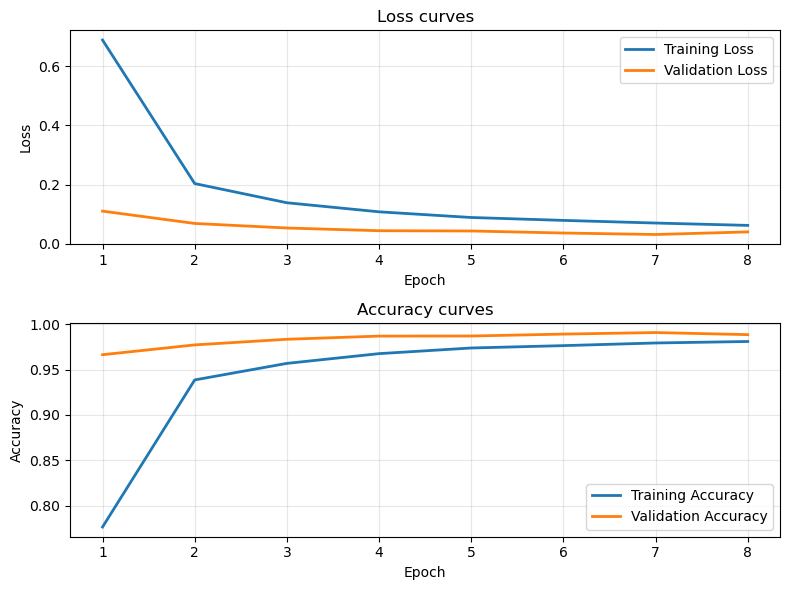

In [31]:
plot_training_history(trace_cnn)

The training for this CNN model went well, demonstrating fast convergence and good generalization. In the loss curves, the training loss decends from about 0.69 down to approximately 0.06. Similarly, the validation loss begins low at 0.11 and tapers off cleanly to around 0.04. This positive progression is mirrored in the accuracy curves, where training accuracy starts at 77% and finishes near 98%, while validation accuracy starts strong at 96% and climbs to near 99%. Ultimately, the smooth, stable paths of both metric pairs confirm a robust optimization process with no notable signs of overfitting

Once the CNN model has been trained, we test it by having it make predictions on the images in the test set

In [32]:
test_loss_cnn, test_accuracy_cnn, probabilities_cnn, y_pred_cnn = get_model_predictions(model_cnn, test_data_cnn)

In [33]:
print(f'Test loss: {test_loss_cnn:.4f}\nTest accuracy: {test_accuracy_cnn:.4f}')

Test loss: 0.0266
Test accuracy: 0.9904


The accuracy (or the percentage of correctly predicted handwritten digits) is **99.04%**

In the following confusion matrix, each row is the true digit, each column is the predicted digit, and each cell shows the count of test samples with that true digit classified as that predicted digit

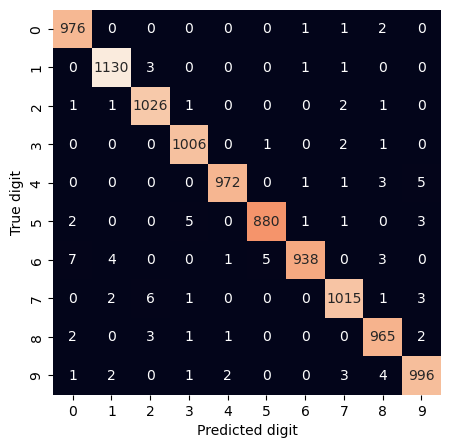

In [34]:
show_confusion_matrix(y_test, y_pred_cnn)

Here is a classification report with some additional per-class metrics

In [35]:
show_classification_report(y_test, y_pred_cnn)

              precision    recall  f1-score   support

           0     0.9869    0.9959    0.9914       980
           1     0.9921    0.9956    0.9938      1135
           2     0.9884    0.9942    0.9913      1032
           3     0.9911    0.9960    0.9936      1010
           4     0.9959    0.9898    0.9928       982
           5     0.9932    0.9865    0.9899       892
           6     0.9958    0.9791    0.9874       958
           7     0.9893    0.9874    0.9883      1028
           8     0.9847    0.9908    0.9877       974
           9     0.9871    0.9871    0.9871      1009

    accuracy                         0.9904     10000
   macro avg     0.9904    0.9902    0.9903     10000
weighted avg     0.9904    0.9904    0.9904     10000



We might also be interested in the digits that the CNN model incorrectly predicted with the highest confidence (very high probability in the winning class, even if it was not the right one). This is important for determining whether the model has any critical flaws or if some of the digits are simply poorly drawn

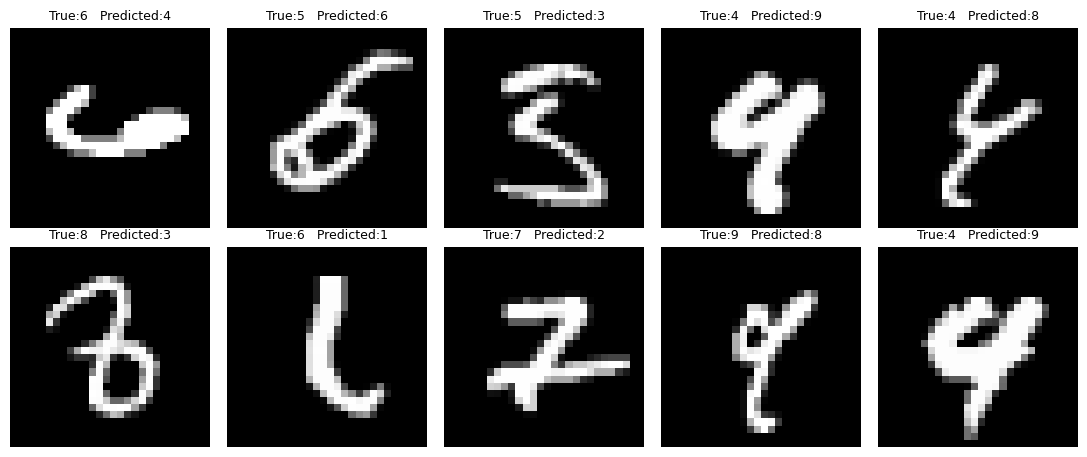

In [36]:
plot_top_confident_wrong_predictions(X_test, y_test, probabilities_cnn, y_pred_cnn, 10)

It is not hard to see why the CNN model gets some specific examples wrong, since even a human might make similar mistakes when looking at digits drawn with unclear strokes

------------------------

### *CONCLUSION*

In this project, we used the MNIST dataset of handwritten digit images to illustrate the data processing workflow and the construction of neural network models. Specifically, we presented a basic MultiLayer Perceptron, a Gated Recurrent Unit network and a Convolutional Neural Network, which present different well-thought-out architectures. After training for the appropriate number of epochs using the training set (50000 samples) and validation set (10000 samples), we have each model predict the digits in the test set (10000 samples) to determine the accuracy

- The proposed *MLP model* achieves an accuracy of **98.04%** on the test set (9804 correct predictions and 196 incorrect predictions)

- The proposed *GRU model* achieves an accuracy of **98.54%** on the test set (9854 correct predictions and 146 incorrect predictions)

- The proposed *CNN model* achieves an accuracy of **99.04%** on the test set (9904 correct predictions and 96 incorrect predictions)

Without using data augmentation, these are practically some of the best results that each respective model can achieve on this dataset. Nevertheless, there is always room for improvement by testing different hyperparameters and topologies

Among the models tested, the MLP model, being a basic model within its family, establishes a good baseline for what a neural network should be capable of achieving at a minimum. On the other hand, the GRU model is a modern model, but its primary area of application is not image recognition. In the area of image classification, the CNN model is the clear winner among the models studied, since it is specifically designed to handle data like that used in this project, and we can achieve a higher accuracy without too much additional effort